# Home Credit Default Risk: EDA

**Goal:** predict whether an applicant will have repayment difficulties (`TARGET = 1`).

This notebook explores the main table, `application_train`, before any modelling: target balance, missing values, anomalies, and how features relate to default. Column meanings are in `data_dictionary.md`.

**Setup.** Import the libraries, set a plot style and load `application_train` into `df`.

In [1]:
# Setup: imports, plot style and load the raw training table
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")  # consistent plot style
pd.set_option("display.max_columns", 50)  # show more columns when printing tables

DATA = "../data/raw/"  # raw data folder, relative to notebooks/
df = pd.read_csv(DATA + "HC_application_train.csv")
df.shape

(307511, 122)

**Insight:** the training table has 307,511 rows and 122 columns.

## 1. Overview

Here we check the column types and look at a few raw rows, to understand what kind of data we are dealing with before any analysis.

In [2]:
# Check column types and preview the first rows
print(df.dtypes.value_counts())  # how many columns of each dtype
df.head()

float64    65
int64      41
str        16
Name: count, dtype: int64


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


**Insight:** the table is mostly numeric (65 float and 41 integer columns) with 16 text columns, which will need encoding for most models.

## 2. Target balance

We count how many applicants default. The balance decides which metric and which train/validation split we can trust.

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


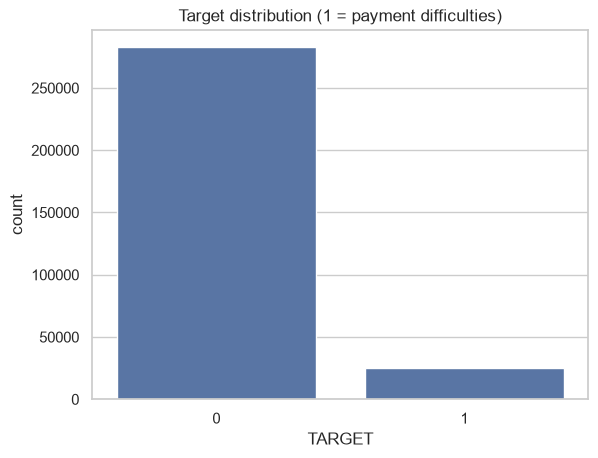

In [3]:
# Count and plot the target classes to measure class imbalance
counts = df["TARGET"].value_counts()
print(counts)
print((df["TARGET"].value_counts(normalize=True) * 100).round(2))  # convert to percentages

ax = sns.countplot(data=df, x="TARGET")
ax.set_title("Target distribution (1 = payment difficulties)")
plt.show()

**Insight:** 24,825 of 307,511 applicants (8.07%) defaulted versus 91.93% who repaid, roughly 11 repaid loans per default. The bar chart shows the same imbalance visually.

The classes are heavily imbalanced, so plain accuracy is misleading (predicting "no default" for everyone is already ~92% accurate). We will use **ROC-AUC** and stratified splits.

## 3. Missing values

We measure how much of each column is missing, because missing data affects which models and imputation steps are sensible.

67 columns have missing values; 41 have more than 50% missing


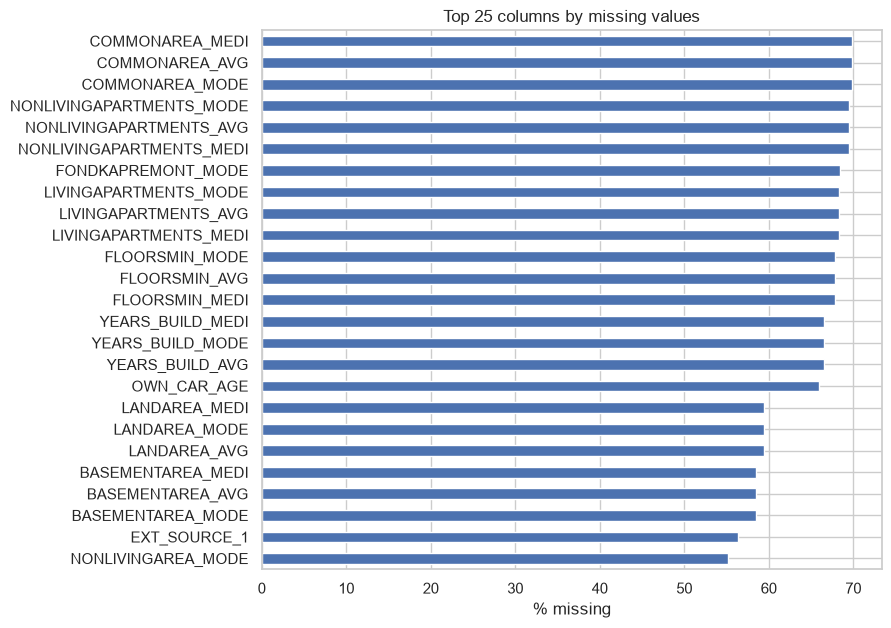

In [4]:
# Share of missing values per column, plotted for the worst 25
missing = (df.isna().mean() * 100).sort_values(ascending=False)  # percent missing per column, worst first
missing = missing[missing > 0]  # keep only columns with any missing
print(f"{len(missing)} columns have missing values; {(missing > 50).sum()} have more than 50% missing")

missing.head(25).sort_values().plot.barh(figsize=(8, 7))  # sort so the worst column is at the top of the bar chart
plt.xlabel("% missing")
plt.title("Top 25 columns by missing values")
plt.show()

Most of the heavily missing columns are the building/housing statistics (`*_AVG`, `*_MODE`, `*_MEDI`). `OWN_CAR_AGE` is 66% missing and `EXT_SOURCE_1` is 56% missing, so even a top predictor has gaps. Tree models handle missing values natively, so we keep them rather than dropping rows.

## 4. Anomalies and cleaning

The first check looks at the known `DAYS_EMPLOYED` placeholder value and whether it behaves differently from normal rows. We do this because a fake number treated as real would distort every model that uses it.

In [5]:
# DAYS_* columns count days back from the application date, so they are negative.
placeholder = df["DAYS_EMPLOYED"] == 365243  # boolean mask of the fake value
print(f"DAYS_EMPLOYED == 365243: {placeholder.sum()} rows ({placeholder.mean() * 100:.1f}%)")
print(df.loc[placeholder, "NAME_INCOME_TYPE"].value_counts())  # who has the placeholder
print()
print("Default rate, placeholder rows:", round(df.loc[placeholder, "TARGET"].mean() * 100, 2), "%")
print("Default rate, other rows:      ", round(df.loc[~placeholder, "TARGET"].mean() * 100, 2), "%")

DAYS_EMPLOYED == 365243: 55374 rows (18.0%)
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

Default rate, placeholder rows: 5.4 %
Default rate, other rows:       8.66 %


**Insight:** 55,374 rows (18.0%) carry the placeholder, and 55,352 of them are pensioners (22 are unemployed). These rows default less often (5.4%) than the rest (8.66%), so the placeholder is informative, not just noise.

Two quick checks on fields that often hide problems: the gender labels and the spread of income.

In [6]:
# Quick sanity checks on gender labels and income range
# Other things worth checking
print(df["CODE_GENDER"].value_counts())  # XNA = unknown gender
print()
print(df["AMT_INCOME_TOTAL"].describe())  # income spread: min, quartiles, max

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64


**Insight:** `CODE_GENDER` has 4 `XNA` rows, too few to matter but worth treating as unknown. Income has a median of 147,150 and a mean of about 168,798, but a maximum of 117,000,000, so a few extreme values pull the mean up.

### Scanning every column for suspicious values

We found the `DAYS_EMPLOYED` placeholder above, but there may be others, so we scan all columns with three checks.

**Scan A: one value repeated a lot, and far outside the rest of the column.** Real data rarely repeats an extreme number thousands of times. Zero is skipped because it is a natural value for counts and amounts. A percentile check would miss this case: the placeholder covers 18% of rows, so it *is* the 99th percentile.

In [7]:
# Scan A: find a single extreme value repeated many times (placeholder candidate)
num_cols = df.select_dtypes("number").columns.drop(["SK_ID_CURR", "TARGET"])  # numeric features without ID and target

rows = []
for col in num_cols:
    s = df[col].dropna()
    if s.nunique() <= 2:                 # skip 0/1 flags
        continue
    vc = s.value_counts()
    top = vc.index[0]  # most frequent value
    rest = s[s != top]  # all other values
    if top != 0 and (top > rest.max() or top < rest.min()):  # flag if the repeated value lies outside the range of the rest
        rows.append({"column": col, "repeated_value": top, "rows": vc.iloc[0],
                     "share_%": round(vc.iloc[0] / len(s) * 100, 2),
                     "rest_min": rest.min(), "rest_max": rest.max()})
pd.DataFrame(rows)

,column,repeated_value,rows,share_%,rest_min,rest_max
0,DAYS_EMPLOYED,365243,55374,18.01,-17912,0


**Insight:** only `DAYS_EMPLOYED` is flagged: the value 365243 appears 55,374 times (18.01%) while all other values lie between -17,912 and 0. No other numeric column has this pattern.

**Scan B: maximum far above the 99th percentile.** These are extreme but real-looking values (outliers). They may be genuine or data-entry errors, so we note them instead of deleting them.

In [8]:
# Scan B: find columns whose maximum is far above the 99th percentile
rows = []
for col in num_cols:
    s = df[col].dropna()
    if s.nunique() <= 2:  # skip 0/1 flags
        continue
    p1, p99 = s.quantile([0.01, 0.99])  # 1st and 99th percentile
    rows.append({"column": col, "median": s.median(), "p99": p99, "max": s.max(),
                 "max_vs_spread": (s.max() - p99) / (p99 - p1 + 1e-9)})  # how many 1-99 percentile spreads the max lies above p99

outliers = pd.DataFrame(rows).sort_values("max_vs_spread", ascending=False)
outliers[outliers["p99"] != outliers["median"]].head(10).round(2)  # drop columns where p99 equals the median (mostly constant)

,column,median,p99,max,max_vs_spread
1,AMT_INCOME_TOTAL,147150.0,472500.00,117000000.0,272.58
70,AMT_REQ_CREDIT_BUREAU_QRT,0.0,2.00,261.0,129.50
61,OBS_30_CNT_SOCIAL_CIRCLE,0.0,10.00,348.0,33.80
63,OBS_60_CNT_SOCIAL_CIRCLE,0.0,10.00,344.0,33.40
62,DEF_30_CNT_SOCIAL_CIRCLE,0.0,2.00,34.0,16.00
64,DEF_60_CNT_SOCIAL_CIRCLE,0.0,2.00,24.0,11.00
44,NONLIVINGAPARTMENTS_MODE,0.0,0.10,1.0,9.28
58,NONLIVINGAPARTMENTS_MEDI,0.0,0.10,1.0,8.54
30,NONLIVINGAPARTMENTS_AVG,0.0,0.11,1.0,8.25
68,AMT_REQ_CREDIT_BUREAU_WEEK,0.0,1.00,8.0,7.00


**Insight:** `AMT_INCOME_TOTAL` stands out (max 117,000,000 against a 99th percentile of 472,500), followed by credit-bureau and social-circle counts (for example max 348 versus p99 of 10). These look like genuine extremes or entry errors, and we keep them rather than delete rows.

**Scan C: text columns with "missing-like" labels** such as `XNA` or `Unknown`, which pandas does not treat as missing.

In [9]:
# Scan C: count text values that mean 'missing' but are not NaN
suspicious = {"XNA", "Unknown", "unknown", "N/A", "NA", "None", "?", ""}  # labels that usually mean missing
for col in df.select_dtypes(include=["object", "string"]).columns:
    hits = df[col].isin(suspicious).sum()  # rows matching those labels
    if hits:
        print(f"{col}: {hits} rows")

CODE_GENDER: 4 rows
NAME_FAMILY_STATUS: 2 rows
ORGANIZATION_TYPE: 55374 rows


**Insight:** `ORGANIZATION_TYPE` has 55,374 `XNA` rows, the same count as the `DAYS_EMPLOYED` placeholder, which suggests the same group of applicants (the equal count is the only evidence here). `CODE_GENDER` has 4 and `NAME_FAMILY_STATUS` has 2 such rows.

**Cleaning.** We turn the placeholder into a missing value (keeping a flag so the information is not lost) and convert the day counts into years so they are easier to read.

In [10]:
# Cleaning: keep "no job" as a flag, turn the fake value into NaN, convert days to years.
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)  # flag column kept, since the placeholder itself carries signal
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)  # fake value becomes NaN

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365  # days are negative, so flip sign; 365 days per year
df["YEARS_EMPLOYED"] = -df["DAYS_EMPLOYED"] / 365

df[["AGE_YEARS", "YEARS_EMPLOYED"]].describe()  # check the converted columns look plausible

/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_60532/13890604.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_60532/13890604.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365
/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_60532/13890604.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of callin

,AGE_YEARS,YEARS_EMPLOYED
count,307511.000000,252137.000000
mean,43.936973,6.531971
std,11.956133,6.406466
min,20.517808,-0.000000
25%,34.008219,2.101370
50%,43.150685,4.515068
75%,53.923288,8.698630
max,69.120548,49.073973


**Insight:** ages range from about 20.5 to 69.1 years (mean 43.9). `YEARS_EMPLOYED` has 252,137 valid values after the placeholder became NaN, with a median of 4.5 years and a maximum of 49.1. The PerformanceWarning text is harmless: it only notes that adding columns one by one fragments the DataFrame. The `-0.000` minimum is just negative zero from the sign flip.

## 5. Default rate by category

We compare default rates across groups of each categorical feature against the overall rate, to see which groups are riskier.

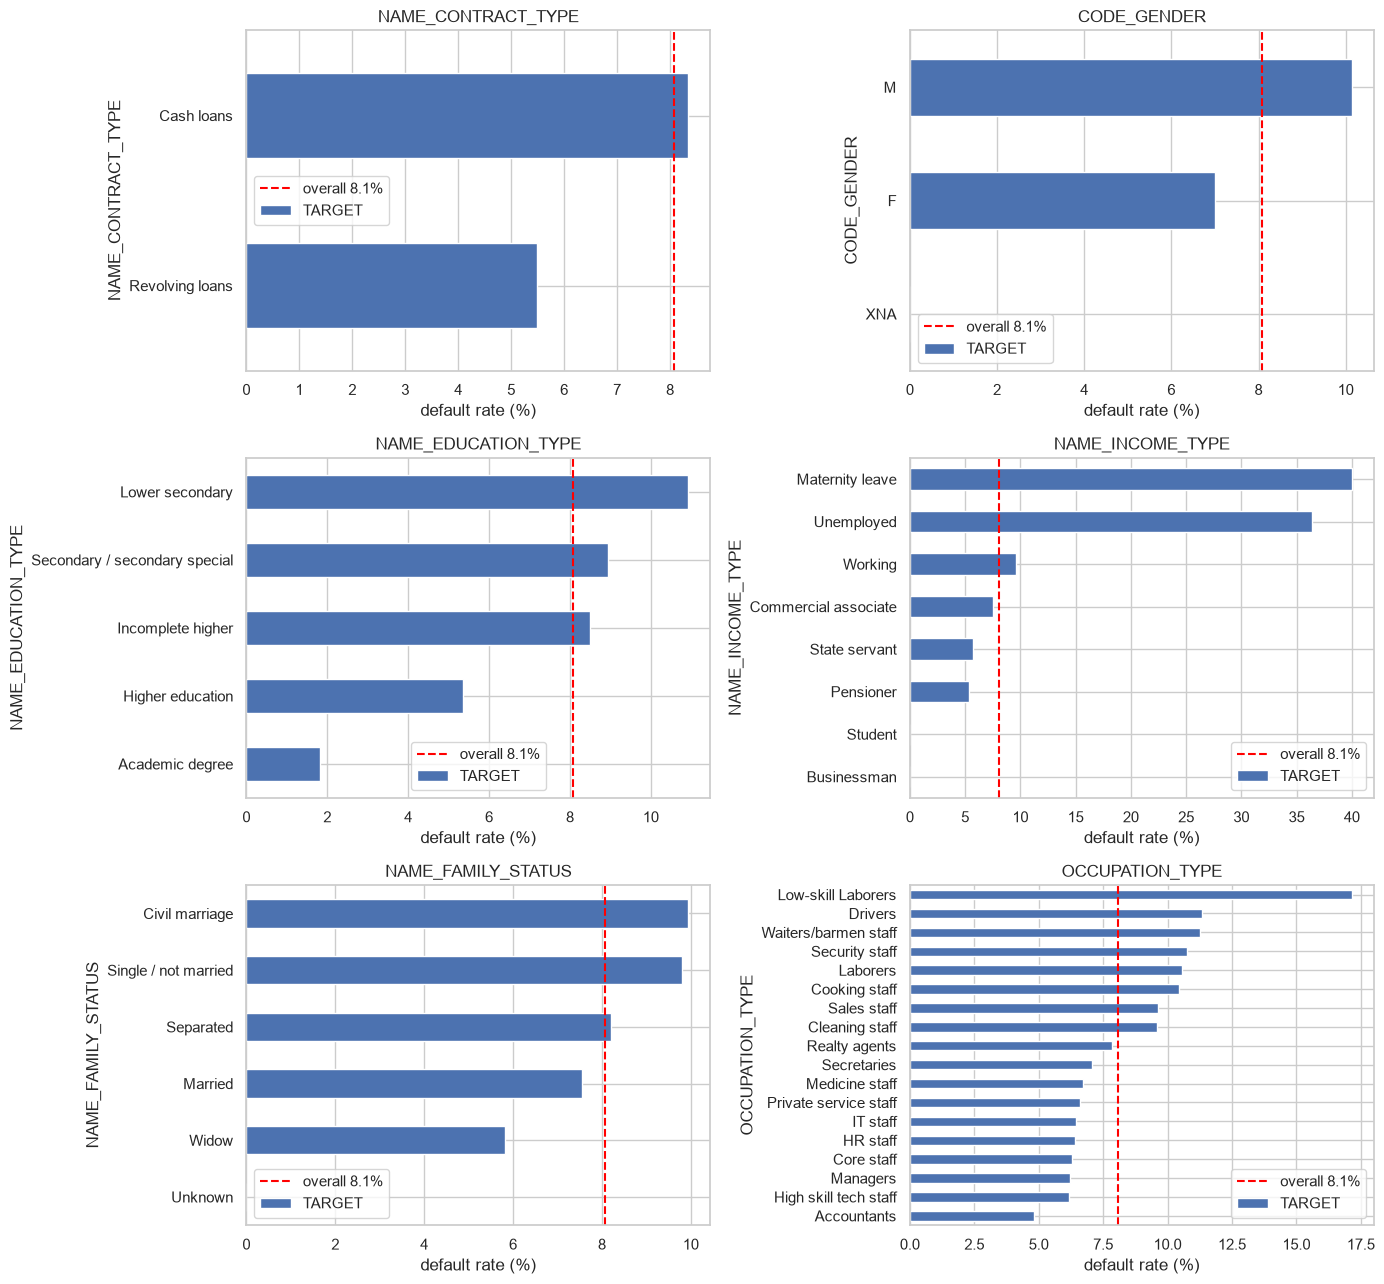

In [11]:
# Default rate per category for six categorical features
cat_cols = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_EDUCATION_TYPE",
            "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS", "OCCUPATION_TYPE"]
overall = df["TARGET"].mean() * 100  # overall default rate, used as reference line

fig, axes = plt.subplots(3, 2, figsize=(14, 13))  # 3x2 grid, one panel per feature
for ax, col in zip(axes.ravel(), cat_cols):
    rate = (df.groupby(col)["TARGET"].mean() * 100).sort_values()  # default rate per category, sorted
    rate.plot.barh(ax=ax)
    ax.axvline(overall, color="red", linestyle="--", label=f"overall {overall:.1f}%")  # red line = overall rate
    ax.set_title(col)
    ax.set_xlabel("default rate (%)")
    ax.legend()
plt.tight_layout()
plt.show()

**Insight:** The chart is an image and its bar values are not printed, so this reads only what the code plots. Each panel shows default rate by category with a red line at the overall rate of 8.07%. Bars to the right of the line mark riskier groups and bars to the left safer ones. The exact ranking is not stated here.

`ORGANIZATION_TYPE` has too many categories for the grid above, so we plot it separately and keep only groups with enough applicants for a stable rate.

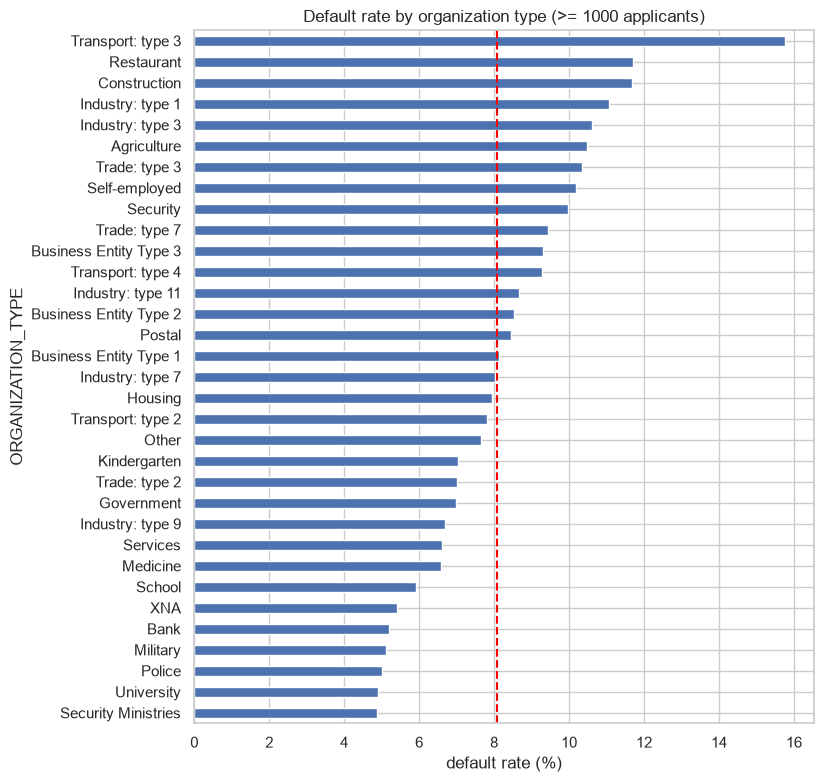

In [12]:
# ORGANIZATION_TYPE has many categories: show only those with enough applicants
g = df.groupby("ORGANIZATION_TYPE")["TARGET"].agg(["mean", "size"])  # mean rate and group size
g = g[g["size"] >= 1000].sort_values("mean")  # drop small groups: their rates are noisy
(g["mean"] * 100).plot.barh(figsize=(8, 9))
plt.axvline(overall, color="red", linestyle="--")
plt.xlabel("default rate (%)")
plt.title("Default rate by organization type (>= 1000 applicants)")
plt.show()

**Insight:** The chart is an image and its bar values are not printed, so this reads only what the code plots. Organizations are sorted by default rate against the overall 8.07% line, restricted to groups of at least 1,000 applicants so that rates are not driven by tiny samples.

## 6. Numeric features vs target

We compare how numeric features are distributed for repaid versus defaulted loans. Features whose curves differ are likely to be useful predictors.

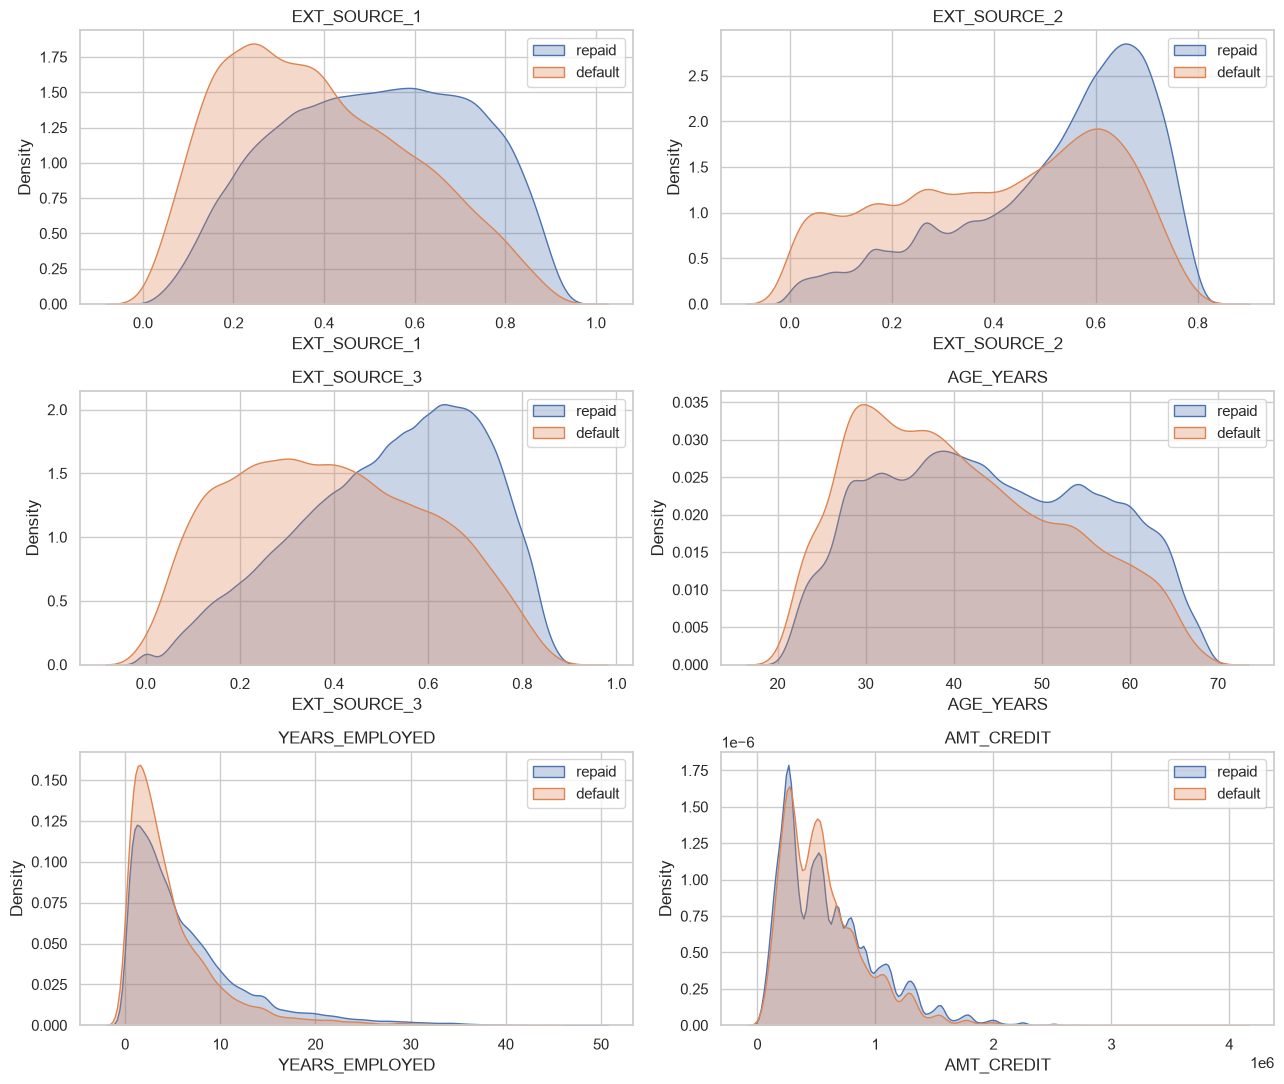

In [13]:
# Compare distributions of key numeric features for repaid vs default
num_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
            "AGE_YEARS", "YEARS_EMPLOYED", "AMT_CREDIT"]

fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for ax, col in zip(axes.ravel(), num_cols):
    for t, label in [(0, "repaid"), (1, "default")]:
        sns.kdeplot(df.loc[df["TARGET"] == t, col].dropna(), ax=ax, label=label, fill=True, alpha=0.3)  # density per class, missing values dropped
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**Insight:** The chart is an image and its bar values are not printed, so this reads only what the code plots. Each panel overlays the density for repaid and defaulted loans. Where the two curves separate, the feature carries signal. The key findings below name the `EXT_SOURCE` scores as the clearest separators.

Income is very skewed, as the maximum above showed. A log scale shows the shape of the bulk of the data.

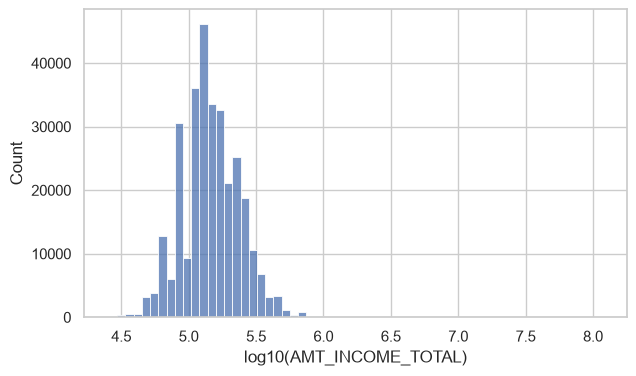

In [14]:
# Income is heavily skewed: look at it on a log scale
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(np.log10(df["AMT_INCOME_TOTAL"]), bins=60, ax=ax)  # log scale makes the skewed income readable
ax.set_xlabel("log10(AMT_INCOME_TOTAL)")
plt.show()

**Insight:** The chart is an image and its bar values are not printed, so this reads only what the code plots. After the log transform the bulk of incomes can be seen on one readable axis, while the long right tail seen in the 117,000,000 maximum is compressed.

## 7. Correlation with the target

We rank numeric features by their linear correlation with `TARGET` as a quick, rough signal check. This misses non-linear effects, so it is only a first look.

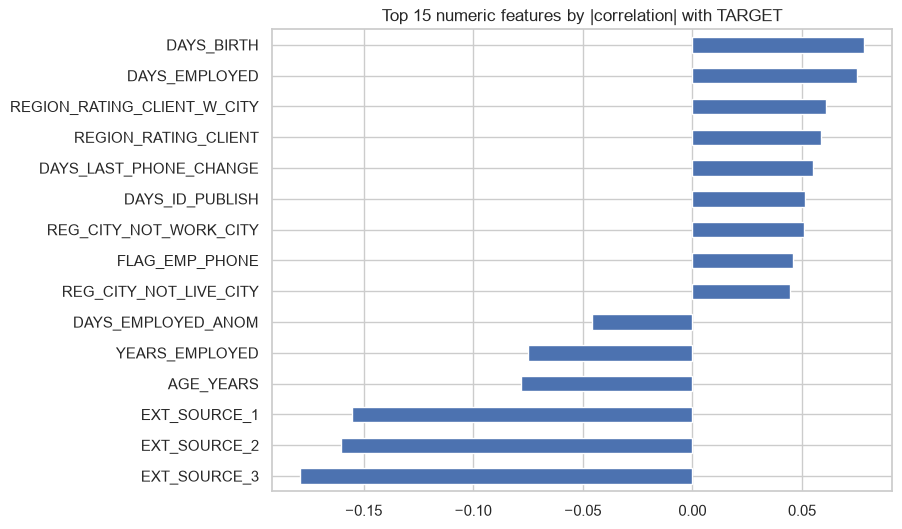

In [15]:
# Rank numeric features by absolute correlation with TARGET
corr = df.select_dtypes("number").corr()["TARGET"].drop("TARGET")  # correlation of every numeric column with TARGET
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)  # order by strength, ignore sign
top.sort_values().plot.barh(figsize=(8, 6))  # sort so the strongest is at the top of the bar chart
plt.title("Top 15 numeric features by |correlation| with TARGET")
plt.show()

**Insight:** The chart is an image and its bar values are not printed, so this reads only what the code plots. The bars show the 15 numeric features with the strongest linear correlation with `TARGET`. Correlations on a default problem are typically small, and this does not capture non-linear effects. The key findings below point to the `EXT_SOURCE` scores as the strongest signals.

## Key findings

- **Imbalance:** 8.07% of 307,511 applicants default (24,825 loans), so we evaluate with ROC-AUC and stratified splits.
- **Missing data:** 67 columns have missing values and 41 are over 50% missing, mostly housing statistics. `EXT_SOURCE_1` is 56% missing.
- **Placeholder:** `DAYS_EMPLOYED = 365243` affects 55,374 rows (18%), almost all pensioners. That group defaults less (5.4% vs 8.66%), so we keep it as a flag (`DAYS_EMPLOYED_ANOM`) and set the value to NaN.
- **Data quality:** `CODE_GENDER` has 4 `XNA` rows. `AMT_INCOME_TOTAL` is heavily skewed (max 117 million vs median 147,150).
- **Signals:** the `EXT_SOURCE` scores separate defaulters from non-defaulters most clearly, in line with the baseline SHAP result.

**Next:** feature engineering (ratios, bureau and previous-application aggregates) and proper cross-validation.